# 03 Vehicle allocation (linear programming, by region and time of day)
Reallocate each region's fixed fleet across its LSOAs to minimise **gap-weighted unmet demand**.

**Important:** demand is *estimated* from population and a trip rate, not observed occupancy.

**Regions.** Buses cannot move freely across England, so the model is solved **separately for London, the metropolitan areas and the non-metropolitan areas**, each with its own fleet, journeys and productivity from DfT annual bus statistics (year ending March 2025).

Model, for LSOA *i* in a region:
- `x_i` = vehicles allocated (continuous), `u_i` = unmet demand
- minimise  sum(`w_i` * `u_i`)  where `w_i` = demand-gap score
- `u_i >= D_i - C * x_i`, `u_i >= 0`
- sum(`x_i`) <= region fleet, `x_i >= floor * x0_i` (protect existing service), `x_i <= cap_i` (no over-provision)

In [1]:
from pathlib import Path
import numpy as np, pandas as pd, pulp
import matplotlib.pyplot as plt
CLEAN = Path("../data/clean")
df = pd.read_parquet(CLEAN / "lsoa_score.parquet")
df.shape

(33755, 22)

## 1. Regions
Each LSOA is assigned to London, a metropolitan area or a non-metropolitan area from its local authority (the name before the LSOA code).

In [2]:
LONDON = ["Barking and Dagenham", "Barnet", "Bexley", "Brent", "Bromley", "Camden", "City of London", "Croydon", "Ealing", "Enfield",
          "Greenwich", "Hackney", "Hammersmith and Fulham", "Haringey", "Harrow", "Havering", "Hillingdon", "Hounslow", "Islington",
          "Kensington and Chelsea", "Kingston upon Thames", "Lambeth", "Lewisham", "Merton", "Newham", "Redbridge",
          "Richmond upon Thames", "Southwark", "Sutton", "Tower Hamlets", "Waltham Forest", "Wandsworth", "Westminster"]
METRO = ["Bolton", "Bury", "Manchester", "Oldham", "Rochdale", "Salford", "Stockport", "Tameside", "Trafford", "Wigan",     # Greater Manchester
         "Knowsley", "Liverpool", "St. Helens", "Sefton", "Wirral",                                                    # Merseyside
         "Barnsley", "Doncaster", "Rotherham", "Sheffield",                                                            # South Yorkshire
         "Gateshead", "Newcastle upon Tyne", "North Tyneside", "South Tyneside", "Sunderland",                         # Tyne and Wear
         "Birmingham", "Coventry", "Dudley", "Sandwell", "Solihull", "Walsall", "Wolverhampton",                       # West Midlands
         "Bradford", "Calderdale", "Kirklees", "Leeds", "Wakefield"]                                                   # West Yorkshire
# Local authority = LSOA name without its trailing code, e.g. "Darlington 001A" becomes "Darlington"
df["la"] = df["LSOA21NM"].str.rsplit(" ", n=1).str[0]
assert set(LONDON) <= set(df.la) and set(METRO) <= set(df.la), "a local authority name did not match"
df["region"] = np.where(df.la.isin(LONDON), "London", np.where(df.la.isin(METRO), "Metropolitan", "Non-metropolitan"))
df.groupby("region").agg(lsoas=("LSOA21CD", "size"), population=("population", "sum"))

,lsoas,population
region,,
London,4994,9089736
Metropolitan,7335,12566058
Non-metropolitan,21426,36964307


## 2. Assumptions (calibrated to DfT annual bus statistics, year ending March 2025)
Source: DfT (2025), *Annual bus statistics: year ending March 2025 (revised)*.

- Demand per resident = region journeys / 365 / region population, so each region's total demand equals its observed journeys.
- Productivity per bus = region journeys per day / region fleet (a derived average, not a capacity limit).

In [3]:
REGIONS = {   # journeys and fleet by area type, England
    "London":           {"journeys": 1.82e9, "fleet": 8_913},
    "Metropolitan":     {"journeys": 0.78e9, "fleet": 7_899},
    "Non-metropolitan": {"journeys": 1.07e9, "fleet": 13_745},
}
FLOOR, OVERSUPPLY = 0.5, 1.2     # keep >= 50% of today's allocation; never allocate > 120% of what demand needs
pop = df.groupby("region")["population"].sum()
for r, P in REGIONS.items():
    P["trips_pp_day"] = P["journeys"] / 365 / pop[r]          # journeys per resident per day
    P["pax_per_bus_day"] = P["journeys"] / 365 / P["fleet"]   # journeys per bus per day
# Demand per neighbourhood = residents x the region type's journeys per resident per day
df["demand"] = df["population"] * df["region"].map({r: P["trips_pp_day"] for r, P in REGIONS.items()})
pd.DataFrame(REGIONS).T[["journeys", "fleet", "trips_pp_day", "pax_per_bus_day"]].round(3)

,journeys,fleet,trips_pp_day,pax_per_bus_day
London,1.820000e+09,8913.0,0.549,559.441
Metropolitan,7.800000e+08,7899.0,0.170,270.539
Non-metropolitan,1.070000e+09,13745.0,0.079,213.278


## 3. Solver

In [4]:
def solve(gap, demand, x0, fleet, cap, floor=FLOOR, over=OVERSUPPLY):
    """One linear programme. Inputs are numpy arrays (per LSOA) and scalars. Returns (status, allocation)."""
    n = len(gap)
    # Lower bound: every area keeps at least half of today's buses
    lo = floor * x0
    # Upper bound: no area gets more than 120% of what its demand needs (and never less than its floor)
    hi = np.maximum(over * demand / cap, lo)
    m = pulp.LpProblem("allocation", pulp.LpMinimize)
    x = [m.add_variable(f"x{i}", lowBound=float(lo[i]), upBound=float(hi[i])) for i in range(n)]
    u = [m.add_variable(f"u{i}", lowBound=0) for i in range(n)]
    # Objective: minimise unmet demand, weighted by the gap score so unmet demand in high-gap areas costs more
    m += pulp.lpSum(float(gap[i]) * u[i] for i in range(n))
    for i in range(n):
        # Unmet demand = demand the allocated buses cannot carry (u >= demand - capacity x buses, and u >= 0)
        m += u[i] >= float(demand[i]) - cap * x[i]
    # The total number of buses in the region cannot exceed its fleet
    m += pulp.lpSum(x) <= fleet
    r = m.solve(pulp.HiGHS(msg=False))
    return r.status_str, np.array([v.value() for v in x])

def run_daily(d, fleet_mult=1.0, prod_mult=1.0):
    parts = []
    for r, g in d.groupby("region"):
        P = REGIONS[r]; fleet = P["fleet"] * fleet_mult; cap = P["pax_per_bus_day"] * prod_mult
        # Today's allocation: the fleet shared out in proportion to timetable frequency (real bus-to-area assignments are not public)
        x0 = fleet * g["freq_mean"].values / g["freq_mean"].sum()
        dem = g["demand"].values
        st, xv = solve(g["gap_score"].values, dem, x0, fleet, cap)
        parts.append(pd.DataFrame({"LSOA21CD": g["LSOA21CD"].values, "region": r, "status": st, "x0": x0, "x_opt": xv,
                                   "unmet0": np.clip(dem - cap * x0, 0, None), "unmet_opt": np.clip(dem - cap * xv, 0, None)}))
    return pd.concat(parts, ignore_index=True)

## 4. Daily model: results by region

In [5]:
daily = run_daily(df)
print("Solver status:", daily.groupby("region")["status"].first().to_dict())
res = daily.merge(df[["LSOA21CD", "demand", "gap_top10"]], on="LSOA21CD")
reg = res.groupby("region").agg(demand=("demand", "sum"), unmet_baseline=("unmet0", "sum"), unmet_optimised=("unmet_opt", "sum"))
reg["share_unmet_baseline"] = reg.unmet_baseline / reg.demand; reg["share_unmet_optimised"] = reg.unmet_optimised / reg.demand
reg["reduction"] = 1 - reg.unmet_optimised / reg.unmet_baseline
reg.loc["England"] = [reg.demand.sum(), reg.unmet_baseline.sum(), reg.unmet_optimised.sum(),
                      reg.unmet_baseline.sum() / reg.demand.sum(), reg.unmet_optimised.sum() / reg.demand.sum(),
                      1 - reg.unmet_optimised.sum() / reg.unmet_baseline.sum()]
reg.round(3)

Running HiGHS 1.16.0 (git hash: f3f113d): Copyright (c) 2026 under MIT licence terms
Includes third-party software components, see THIRD_PARTY_NOTICES.md for full details


Solver status: {'London': 'Optimal', 'Metropolitan': 'Optimal', 'Non-metropolitan': 'Optimal'}


,demand,unmet_baseline,unmet_optimised,share_unmet_baseline,share_unmet_optimised,reduction
region,,,,,,
London,4.986301e+06,2033843.666,463308.255,0.408,0.093,0.772
Metropolitan,2.136986e+06,748432.386,162416.679,0.350,0.076,0.783
Non-metropolitan,2.931507e+06,1152599.177,284604.203,0.393,0.097,0.753
England,1.005479e+07,3934875.230,910329.137,0.391,0.091,0.769


In [6]:
t = res.groupby("gap_top10")[["unmet0", "unmet_opt"]].sum().rename(index={False: "Other 90%", True: "Top 10% gap"})
t["reduction"] = 1 - t["unmet_opt"] / t["unmet0"]; t.round(3)

,unmet0,unmet_opt,reduction
gap_top10,,,
Other 90%,2788974.424,910329.137,0.674
Top 10% gap,1145900.806,0.000,1.000


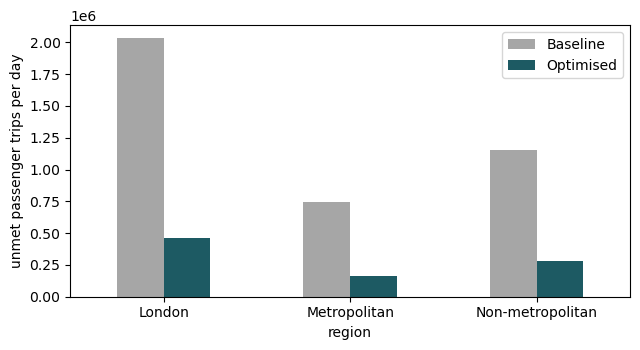

In [7]:
fig, ax = plt.subplots(figsize=(6.5, 3.6))
reg.drop(index="England")[["unmet_baseline", "unmet_optimised"]].plot.bar(ax=ax, rot=0, color=["#a6a6a6", "#1d5a63"])
ax.set_ylabel("unmet passenger trips per day"); ax.legend(["Baseline", "Optimised"]); plt.tight_layout()

## 5. Sensitivity to fleet size and productivity
Each region's fleet and journeys per bus are scaled to 80%, 100% and 120%.

In [8]:
rows = []
for fm in [0.8, 1.0, 1.2]:
    for pm in [0.8, 1.0, 1.2]:
        r_ = run_daily(df, fm, pm)
        rows.append({"fleet_pct": int(fm * 100), "productivity_pct": int(pm * 100),
                     "unmet baseline": r_.unmet0.sum(), "unmet optimised": r_.unmet_opt.sum(),
                     "reduction": 1 - r_.unmet_opt.sum() / r_.unmet0.sum()})
sens = pd.DataFrame(rows); sens.round(3)

,fleet_pct,productivity_pct,unmet baseline,unmet optimised,reduction
0,80,80,5215234.043,3919658.939,0.248
1,80,100,4559788.314,2541086.124,0.443
2,80,120,4045442.310,1229428.858,0.696
3,100,80,4559788.314,2541086.124,0.443
4,100,100,3934875.230,910329.137,0.769
5,100,120,3466174.787,0.000,1.000
6,120,80,4045442.310,1229428.858,0.696
7,120,100,3466174.787,0.000,1.000
8,120,120,3039734.828,0.000,1.000


## 6. Time-band allocation
The same model solved **separately for each time band** (morning 07-10, off-peak 10-16, evening 16-19), still region by region, so vehicles can move between neighbourhoods *and* between bands.

- Demand per hour = daily demand / 12 service hours, optionally weighted for peaks (`peak_uplift`; 1.0 = flat). Peak bands get `p`, off-peak gets `2 - p`, so the 12-hour total is unchanged.
- Capacity per vehicle-hour = productivity / 12.
- Baseline in each band follows that band's scheduled departures (GTFS). The full regional fleet is available in each band; bands are independent problems.

In [9]:
HOURS = {"morning": 3, "off_peak": 6, "evening": 3}
COL = {"morning": "freq_morning", "off_peak": "freq_off_peak", "evening": "freq_evening"}
def run_bands(peak_uplift=1.0, d=None):
    d = df if d is None else d
    w = {"morning": peak_uplift, "evening": peak_uplift, "off_peak": 2 - peak_uplift}
    wide = {}; rows = []
    for b, h in HOURS.items():
        parts = []
        for r, g in d.groupby("region"):
            P = REGIONS[r]; fleet = P["fleet"]; cap = P["pax_per_bus_day"] / 12
            x0 = fleet * g[COL[b]].values / g[COL[b]].sum()
            dem = g["demand"].values / 12 * w[b]
            st, xv = solve(g["gap_score"].values, dem, x0, fleet, cap)
            parts.append(pd.DataFrame({"LSOA21CD": g["LSOA21CD"].values, f"x0_{b}": x0, f"xopt_{b}": xv,
                                       f"unmet0_{b}": np.clip(dem - cap * x0, 0, None), f"unmet_opt_{b}": np.clip(dem - cap * xv, 0, None)}))
        p = pd.concat(parts, ignore_index=True); wide[b] = p
        rows.append({"band": b, "hours": h, "unmet/day baseline": p[f"unmet0_{b}"].sum() * h, "unmet/day optimised": p[f"unmet_opt_{b}"].sum() * h})
    out = wide["morning"]
    for b in ["off_peak", "evening"]:
        out = out.merge(wide[b], on="LSOA21CD")
    return out, pd.DataFrame(rows)
bands, bsum = run_bands(1.0)
tot = bsum[["unmet/day baseline", "unmet/day optimised"]].sum()
print(f"Time-band model, unmet demand per day: baseline {tot.iloc[0]:,.0f} -> optimised {tot.iloc[1]:,.0f} ({1 - tot.iloc[1]/tot.iloc[0]:.0%} lower)")
bsum.round(0)

Time-band model, unmet demand per day: baseline 3,940,277 -> optimised 911,518 (77% lower)


,band,hours,unmet/day baseline,unmet/day optimised
0,morning,3,983683.0,227009.0
1,off_peak,6,1966581.0,454031.0
2,evening,3,990013.0,230478.0


### Who gains vehicles in which band?
Net change in vehicles (optimised minus baseline) summed over neighbourhoods, by service-pattern cluster from notebook 05.

In [10]:
cl = pd.read_parquet(CLEAN / "lsoa_clusters.parquet")[["LSOA21CD", "cluster"]]
bb = bands.merge(cl, on="LSOA21CD")
chg = pd.DataFrame({b: bb[f"xopt_{b}"] - bb[f"x0_{b}"] for b in HOURS}).assign(cluster=bb["cluster"]).groupby("cluster").sum().round(0)
chg["n_lsoas"] = bb.groupby("cluster").size()
chg

,morning,off_peak,evening,n_lsoas
cluster,,,,
-1,2412.0,2412.0,2412.0,2348
0,6117.0,6106.0,6082.0,15023
1,-9157.0,-9125.0,-9182.0,15278
2,371.0,321.0,390.0,628
3,257.0,286.0,298.0,478


### Sensitivity: peak demand uplift
Peak bands carrying 25% more demand per hour than a flat profile.

In [11]:
rows = []
for p in [1.0, 1.25]:
    _, s_ = run_bands(p)
    t = s_[["unmet/day baseline", "unmet/day optimised"]].sum()
    rows.append({"peak_uplift": p, "unmet/day baseline": t.iloc[0], "unmet/day optimised": t.iloc[1], "reduction": 1 - t.iloc[1] / t.iloc[0]})
band_sens = pd.DataFrame(rows); band_sens.round(3)

,peak_uplift,unmet/day baseline,unmet/day optimised,reduction
0,1.00,3940276.781,911518.147,0.769
1,1.25,4060323.078,1590332.790,0.608


## 7. Alternative demand: observed bus use by local authority
The base model assumes demand follows population inside each region type. That is the main weakness (see the DfT check in notebook 08): strong-network places such as Nottingham or Brighton carry far more journeys per head.
This section re-runs the model with demand scaled to **observed journeys per head** from DfT BUS01e (year ending March 2025) wherever it is published:
- unitary authorities, matched by name;
- the six metropolitan combined authorities, shared across their districts by population;
- everywhere else (London boroughs and districts in two-tier counties, not published) gets the journeys left over in its region type, shared by population.
Each region type's total is rescaled to the same DfT figure as before, so fleet and total journeys are unchanged. Only the *distribution* of demand differs.

In [12]:
import re
RAWD = Path("../data/raw/dft_bus_tables")
b = pd.read_excel(RAWD / "bus01.ods", engine="odf", sheet_name="BUS01e", header=8)
c25 = [c for c in b.columns if str(c).strip() == "2025"][0]
b = b[["Local Authority (LA) Code", "LA or Region", c25]]; b.columns = ["code", "name", "m"]
b["per_day"] = pd.to_numeric(b["m"], errors="coerce") * 1e6 / 365
norm = lambda s: re.sub(r"[^a-z]", "", s.lower().replace(", city of", "").replace(", county of", "").replace("city of ", ""))
CA = {"Greater Manchester CA": METRO[0:10], "Merseyside CA": METRO[10:15], "South Yorkshire CA": METRO[15:19],
      "Tyne and Wear CA": METRO[19:24], "West Midlands CA": METRO[24:31], "West Yorkshire CA": METRO[31:36]}
laT = df.groupby("la").agg(pop=("population", "sum"), region=("region", "first")).reset_index()
laT["obs"] = np.nan
u = b[b["code"].astype(str).str.startswith("E06")].copy(); u["k"] = u["name"].map(norm).replace({"durham": "countydurham"})
laT["k"] = laT["la"].map(norm); laT["obs"] = laT["k"].map(dict(zip(u["k"], u["per_day"])))
for nm, las in CA.items():
    tot = b.loc[b["name"] == nm, "per_day"].iloc[0]; sel = laT["la"].isin(las)
    laT.loc[sel, "obs"] = tot * laT.loc[sel, "pop"] / laT.loc[sel, "pop"].sum()
laT["observed"] = laT["obs"].notna()
for r, P in REGIONS.items():
    tot = P["journeys"] / 365; s = laT["region"] == r; kn = s & laT["observed"]; un = s & ~laT["observed"]
    if un.any():
        resid = max(tot - laT.loc[kn, "obs"].sum(), 0.10 * tot)
        laT.loc[un, "obs"] = resid * laT.loc[un, "pop"] / laT.loc[un, "pop"].sum()
    laT.loc[s, "obs"] *= tot / laT.loc[s, "obs"].sum()          # same regional total as the base model
laT["rate"] = laT["obs"] / laT["pop"]
df["demand_obs"] = df["population"] * df["la"].map(dict(zip(laT["la"], laT["rate"])))
cov = laT.groupby("region").apply(lambda g: pd.Series({"LAs": len(g), "with observed data": int(g.observed.sum()),
        "population share observed": g.loc[g.observed, "pop"].sum() / g["pop"].sum()}))
print(cov.round(2)); print(df.groupby("region")[["demand", "demand_obs"]].sum().round(0))
laT.sort_values("rate")[["la", "region", "observed", "rate"]].iloc[[0, 1, 2, -3, -2, -1]].round(3)

                    LAs  with observed data  population share observed
region                                                                
London             33.0                 0.0                       0.00
Metropolitan       36.0                36.0                       1.00
Non-metropolitan  240.0                56.0                       0.39
                     demand  demand_obs
region                                 
London            4986301.0   4986301.0
Metropolitan      2136986.0   2136986.0
Non-metropolitan  2931507.0   2931507.0


/var/folders/lg/9qwzgs8570s69v83k7zz0yvh0000gn/T/ipykernel_22817/1197223663.py:26: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  cov = laT.groupby("region").apply(lambda g: pd.Series({"LAs": len(g), "with observed data": int(g.observed.sum()),


,la,region,observed,rate
212,Rutland,Non-metropolitan,True,0.013
53,Cheshire East,Non-metropolitan,True,0.019
122,Herefordshire,Non-metropolitan,True,0.026
170,Newham,London,False,0.549
111,Hammersmith and Fulham,London,False,0.549
113,Haringey,London,False,0.549


In [13]:
d_obs = df.assign(demand=df["demand_obs"])
daily_obs = run_daily(d_obs)
bands_obs, bsum_obs = run_bands(1.0, d_obs)
t0, t1 = daily_obs.unmet0.sum(), daily_obs.unmet_opt.sum()
print(f"Observed-use demand, daily model: unmet {t0:,.0f} -> {t1:,.0f} ({1 - t1 / t0:.0%} lower)  [population demand: {1 - daily.unmet_opt.sum() / daily.unmet0.sum():.0%}]")
rows = []
for fm in [0.8, 1.0, 1.2]:
    for pm in [0.8, 1.0, 1.2]:
        r_ = run_daily(d_obs, fm, pm)
        rows.append({"fleet_pct": int(fm * 100), "productivity_pct": int(pm * 100), "unmet baseline": r_.unmet0.sum(),
                     "unmet optimised": r_.unmet_opt.sum(), "reduction": 1 - r_.unmet_opt.sum() / r_.unmet0.sum()})
sens_obs = pd.DataFrame(rows)
rows = []
for p in [1.0, 1.25]:
    _, s_ = run_bands(p, d_obs); t = s_[["unmet/day baseline", "unmet/day optimised"]].sum()
    rows.append({"peak_uplift": p, "unmet/day baseline": t.iloc[0], "unmet/day optimised": t.iloc[1], "reduction": 1 - t.iloc[1] / t.iloc[0]})
band_sens_obs = pd.DataFrame(rows)
sens_obs.round(3)

Observed-use demand, daily model: unmet 3,898,166 -> 880,798 (77% lower)  [population demand: 77%]


,fleet_pct,productivity_pct,unmet baseline,unmet optimised,reduction
0,80,80,5179461.941,3901157.171,0.247
1,80,100,4521390.081,2517534.934,0.443
2,80,120,4008600.093,1201116.600,0.700
3,100,80,4521390.081,2517534.934,0.443
4,100,100,3898165.991,880798.424,0.774
5,100,120,3429074.972,0.000,1.000
6,120,80,4008600.093,1201116.600,0.700
7,120,100,3429074.972,0.000,1.000
8,120,120,3002973.675,0.000,1.000


In [14]:
# who changes most between the two demand assumptions? (England, local authorities)
cmp_ = (res.merge(df[["LSOA21CD", "la"]], on="LSOA21CD").groupby("la")[["x0", "x_opt"]].sum()
        .join(daily_obs.merge(df[["LSOA21CD", "la"]], on="LSOA21CD").groupby("la")[["x_opt"]].sum().rename(columns={"x_opt": "x_opt_obs"})))
cmp_["change_pop_pct"] = (cmp_["x_opt"] / cmp_["x0"] - 1) * 100; cmp_["change_obs_pct"] = (cmp_["x_opt_obs"] / cmp_["x0"] - 1) * 100
print("Nottingham:", cmp_.loc["Nottingham", ["x0", "x_opt", "x_opt_obs", "change_pop_pct", "change_obs_pct"]].round(1).to_dict() if "Nottingham" in cmp_.index else "n/a")
cmp_.sort_values("change_pop_pct").round(1).iloc[[0, 1, 2, -3, -2, -1]]

Nottingham: {'x0': 549.6, 'x_opt': 291.6, 'x_opt_obs': 495.1, 'change_pop_pct': -46.9, 'change_obs_pct': -9.9}


,x0,x_opt,x_opt_obs,change_pop_pct,change_obs_pct
la,,,,,
Nottingham,549.6,291.6,495.1,-46.9,-9.9
City of London,105.6,57.1,57.1,-46.0,-46.0
Gedling,134.7,73.2,71.6,-45.6,-46.9
Fenland,10.2,39.0,30.5,281.5,198.0
Hart,8.3,35.0,29.2,322.0,251.6
Isles of Scilly,0.0,0.9,0.7,inf,inf


## 8. Save

In [15]:
out = df.drop(columns=[c for c in ["x0", "x_opt", "unmet0", "unmet_opt"] if c in df.columns]).merge(
    daily[["LSOA21CD", "x0", "x_opt", "unmet0", "unmet_opt"]], on="LSOA21CD").merge(bands, on="LSOA21CD")
obs = daily_obs[["LSOA21CD", "x_opt", "unmet0", "unmet_opt"]].rename(columns={"x_opt": "x_opt_obs", "unmet0": "unmet0_obs", "unmet_opt": "unmet_opt_obs"})
obs = obs.merge(bands_obs[["LSOA21CD", "xopt_morning", "xopt_off_peak", "xopt_evening"]].rename(columns=lambda c: c + "_obs" if c.startswith("xopt") else c), on="LSOA21CD")
out = out.merge(obs, on="LSOA21CD")
out.to_parquet(CLEAN / "lsoa_allocation.parquet", index=False)
sens.to_csv(CLEAN / "allocation_sensitivity.csv", index=False)
bsum.to_csv(CLEAN / "allocation_bands.csv", index=False); band_sens.to_csv(CLEAN / "allocation_bands_sensitivity.csv", index=False)
reg.to_csv(CLEAN / "allocation_regions.csv")
print("saved")
sens_obs.to_csv(CLEAN / "allocation_sensitivity_obs.csv", index=False); band_sens_obs.to_csv(CLEAN / "allocation_bands_sensitivity_obs.csv", index=False); bsum_obs.to_csv(CLEAN / "allocation_bands_obs.csv", index=False)

saved
